# Does a late delivery *cause* bad reviews — and lost customers?

On Olist, late orders get far worse reviews. But late orders are also **different before anything goes wrong**: they
travel further, have shorter promised delivery times, are heavier, and cluster around busy seasons. Any of these could
lower reviews on its own. This notebook separates **causation from correlation** using observational data.

**Treatment:** order delivered after the promised date. **Outcomes:** review score (1–5), negative review (1–2★), and
for a customer's first order, whether they buy again within 6 months.

```
 distance, weight, promised time, season, category, states, price ...   (confounders, known at purchase)
          │                                     │
          ▼                                     ▼
     late delivery  ──────── causal effect? ──────►  review / repeat purchase
```

Only variables known **at purchase time** are used as confounders — nothing that happens after the delivery.

In [1]:
import sys, json
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import statsmodels.api as sm
sys.path.insert(0, str(Path.cwd().parent))
from causal.data import load, design_matrix
from causal.estimators import (naive_diff, ols_adjusted, propensity_scores, ipw, ps_matching_att, aipw,
                               standardized_mean_differences, e_value)
sns.set_theme(style="whitegrid")
REPORTS = Path.cwd().parent / "reports"; REPORTS.mkdir(exist_ok=True)
df = load(); X = design_matrix(df); t = df.late.values
results = {"n_orders": len(df), "late_rate": float(t.mean())}
print(f"{len(df):,} delivered orders, {t.mean():.1%} late, {X.shape[1]} confounder columns")
df.groupby("late")[["review_score", "negative_review"]].mean().round(3)

95,333 delivered orders, 6.6% late, 106 confounder columns


,review_score,negative_review
late,,
0,4.290,0.093
1,2.269,0.625


## 1. Are late orders different before they are late?

In [2]:
summary = df.groupby("late")[["distance_km", "promised_days", "weight_g", "items_value", "freight_value"]].median()
summary.index = ["on time", "late"]
summary.round(1)

,distance_km,promised_days,weight_g,items_value,freight_value
on time,426.4,24.0,682.0,85.0,17.1
late,528.3,23.0,773.0,90.0,18.2


In [3]:
smd_before = standardized_mean_differences(X, t)
results["covariates_imbalanced_before"] = int((smd_before > 0.1).sum())
print(f"{(smd_before > 0.1).sum()} confounders have |standardised mean difference| > 0.1 (imbalanced)")
smd_before.head(10).round(3)

20 confounders have |standardised mean difference| > 0.1 (imbalanced)


purchase_month_3     0.367
customer_state_SP    0.318
purchase_month_6     0.313
customer_state_RJ    0.289
same_state           0.280
log_distance_km      0.274
purchase_month_7     0.228
purchase_month_11    0.225
purchase_month_2     0.218
log_freight_value    0.184
dtype: float64

Yes — late orders come from farther away, got **shorter** promised delivery times, and cluster in busy months: up to **19% of March 2018 orders** were late (14% in February 2018, 12% in the Black-Friday month of November 2017) versus ~7% overall. A fair comparison has to account for this.

## 2. Propensity scores: the probability an order is late, given its confounders

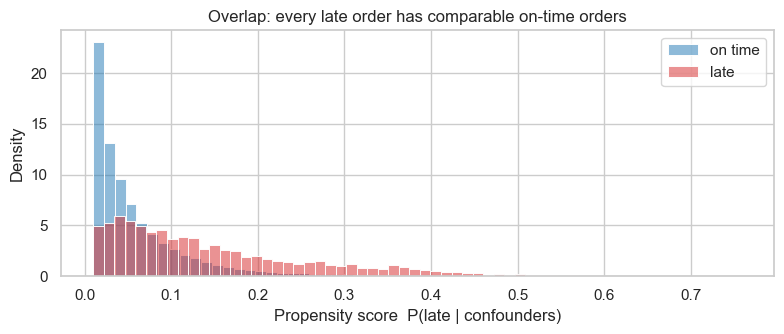

Range 0.010-0.759; mean for late orders 0.147, on time 0.061


In [4]:
ps = propensity_scores(X, t)
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.histplot(ps[t == 0], bins=60, stat="density", color="tab:blue", alpha=0.5, label="on time", ax=ax)
sns.histplot(ps[t == 1], bins=60, stat="density", color="tab:red", alpha=0.5, label="late", ax=ax)
ax.set(xlabel="Propensity score  P(late | confounders)", title="Overlap: every late order has comparable on-time orders")
ax.legend(); fig.tight_layout(); fig.savefig(REPORTS / "propensity_overlap.png", dpi=120); plt.show()
print(f"Range {ps.min():.3f}-{ps.max():.3f}; mean for late orders {ps[t==1].mean():.3f}, on time {ps[t==0].mean():.3f}")

The distributions overlap well, so on-time orders exist that are comparable to late ones — the key requirement (*positivity*) for the methods below.

## 3. Does weighting make the groups comparable? (balance check)

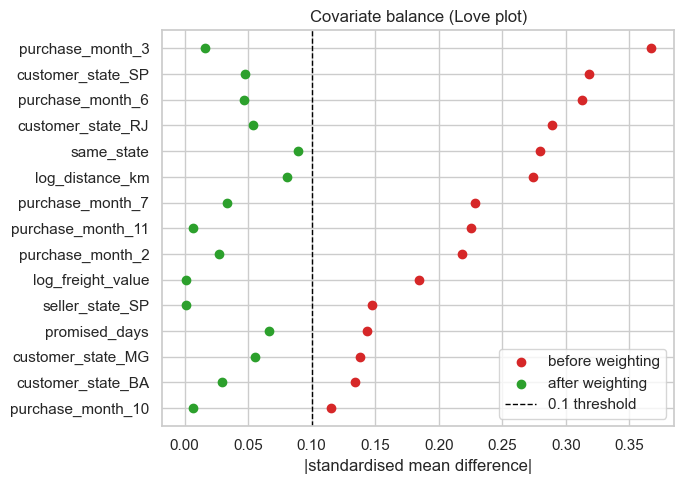

Imbalanced confounders: 20 before -> 0 after weighting (max |SMD| 0.37 -> 0.09)


In [5]:
w = np.where(t == 1, 1 / ps, 1 / (1 - ps))
smd_after = standardized_mean_differences(X, t, w)
results["covariates_imbalanced_after"] = int((smd_after > 0.1).sum())
results["max_smd_before"], results["max_smd_after"] = float(smd_before.max()), float(smd_after.max())
top = smd_before.head(15).index
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(smd_before[top], top, label="before weighting", color="tab:red")
ax.scatter(smd_after[top], top, label="after weighting", color="tab:green")
ax.axvline(0.1, color="black", ls="--", lw=1, label="0.1 threshold")
ax.invert_yaxis(); ax.set(xlabel="|standardised mean difference|", title="Covariate balance (Love plot)")
ax.legend(); fig.tight_layout(); fig.savefig(REPORTS / "love_plot.png", dpi=120); plt.show()
print(f"Imbalanced confounders: {(smd_before>0.1).sum()} before -> {(smd_after>0.1).sum()} after weighting "
      f"(max |SMD| {smd_before.max():.2f} -> {smd_after.max():.2f})")

## 4. The causal effect on reviews — six estimators

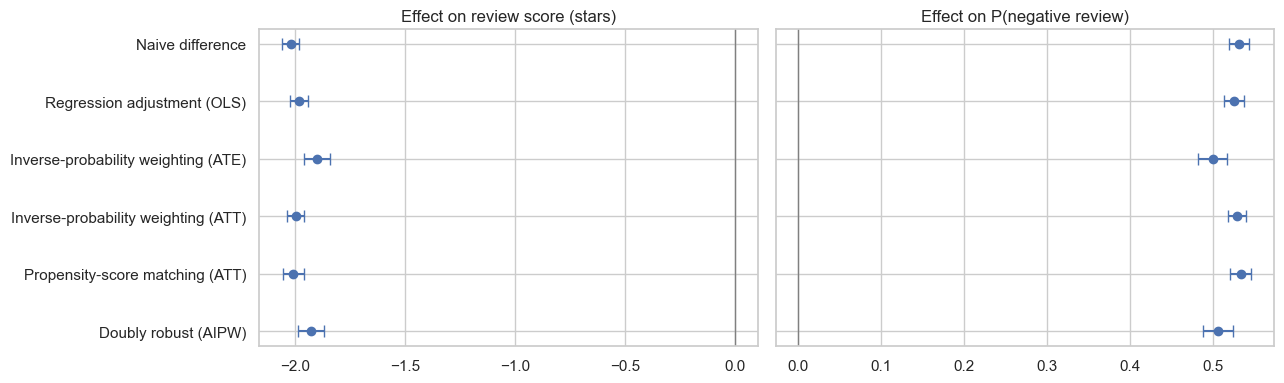

,method,effect,ci_low,ci_high
0,Naive difference,-2.021,-2.061,-1.982
1,Regression adjustment (OLS),-1.982,-2.022,-1.942
2,Inverse-probability weighting (ATE),-1.903,-1.960,-1.842
3,Inverse-probability weighting (ATT),-1.997,-2.036,-1.960
4,Propensity-score matching (ATT),-2.011,-2.054,-1.961
5,Doubly robust (AIPW),-1.930,-1.989,-1.870


In [6]:
def estimate_all(y, X, t, ps, binary):
    rows = [naive_diff(y, t), ols_adjusted(y, t, X), ipw(y, t, ps, "ATE"), ipw(y, t, ps, "ATT"),
            ps_matching_att(y, t, ps)[0]]
    a, mu1, mu0 = aipw(y, t, X, ps, binary)
    rows.append(a)
    return pd.DataFrame([r.__dict__ for r in rows]), mu1, mu0

rev, _, _ = estimate_all(df.review_score.values, X, t, ps, False)
neg, mu1, mu0 = estimate_all(df.negative_review.values, X, t, ps, True)
results["review_effects"] = rev.set_index("method").round(4).to_dict("index")
results["negative_review_effects"] = neg.set_index("method").round(4).to_dict("index")
results["negative_review_rr"] = mu1 / mu0; results["e_value"] = e_value(mu1 / mu0)
fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a_, tab, title in [(ax[0], rev, "Effect on review score (stars)"), (ax[1], neg, "Effect on P(negative review)")]:
    a_.errorbar(tab.effect, tab.method, xerr=[tab.effect - tab.ci_low, tab.ci_high - tab.effect], fmt="o", capsize=4)
    a_.set(title=title); a_.axvline(0, color="grey", lw=1)
ax[0].invert_yaxis(); fig.tight_layout(); fig.savefig(REPORTS / "effect_estimates.png", dpi=120); plt.show()
rev.round(3)

In [7]:
neg.round(3)

,method,effect,ci_low,ci_high
0,Naive difference,0.532,0.520,0.544
1,Regression adjustment (OLS),0.526,0.514,0.538
2,Inverse-probability weighting (ATE),0.500,0.482,0.518
3,Inverse-probability weighting (ATT),0.529,0.518,0.541
4,Propensity-score matching (ATT),0.534,0.521,0.547
5,Doubly robust (AIPW),0.507,0.489,0.524


**Every method agrees**: a late delivery lowers the review by about **2 stars** and raises the chance of a negative
review by about **50 percentage points** (roughly 9% → 60%).

The adjusted estimates are only slightly smaller than the naive one: the confounders strongly affect *whether* an order is
late, but have little direct effect on the review. Here the correlation is almost entirely causal — which the analysis
had to show, not assume.

## 5. Does it matter *how* late? (dose-response)

In [8]:
bins = pd.cut(df.days_vs_promise, [-1000, 0, 3, 7, 14, 1000],
              labels=["on time", "1-3 days late", "4-7 days late", "8-14 days late", "15+ days late"])
D = pd.get_dummies(bins, drop_first=True, dtype=float)
fit = sm.OLS(df.review_score.values, sm.add_constant(pd.concat([D, X], axis=1))).fit(cov_type="HC1")
dose = pd.DataFrame({"effect vs on time (stars)": fit.params[D.columns], "95% CI low": fit.conf_int().loc[D.columns, 0],
                     "95% CI high": fit.conf_int().loc[D.columns, 1], "orders": bins.value_counts()[D.columns]})
results["dose_response"] = dose.round(3).to_dict("index")
dose.round(2)

,effect vs on time (stars),95% CI low,95% CI high,orders
1-3 days late,-0.99,-1.06,-0.92,1841
4-7 days late,-2.17,-2.24,-2.10,1733
8-14 days late,-2.58,-2.65,-2.52,1440
15+ days late,-2.51,-2.58,-2.44,1321


Even **1–3 days late costs about one star**; 4–7 days costs over two, and the damage levels off after about two weeks (reviews cannot fall much further). The promise itself matters: customers judge against the date they were given.

## 6. Could an unmeasured confounder explain this away? (E-value)

In [9]:
print(f"Risk ratio for a negative review, late vs on time (doubly robust): {mu1/mu0:.2f}")
print(f"E-value: {e_value(mu1/mu0):.1f}")

Risk ratio for a negative review, late vs on time (doubly robust): 6.45
E-value: 12.4


An unmeasured confounder (for example, an unreliable seller who is both slow *and* ships poor products) would need to
be associated with **both** lateness and negative reviews by a risk ratio of about **12** — far stronger than any
measured confounder — to explain the effect away. The conclusion is robust.

## 7. Does a late first delivery stop customers from coming back?

In [10]:
f = df[(df.is_first_order == 1) & df.repeat_observable].reset_index(drop=True)
Xf, tf, yf = design_matrix(f), f.late.values, f.bought_again_6m.values.astype(float)
psf = propensity_scores(Xf, tf)
rep, m1, m0 = estimate_all(yf, Xf, tf, psf, True)
results["repeat"] = {"n": len(f), "late": int(tf.sum()), "base_rate": float(yf.mean()),
                     "effects": rep.set_index("method").round(5).to_dict("index")}
print(f"{len(f):,} first orders with 6 months of follow-up ({tf.sum():,} late); 6-month repeat rate {yf.mean():.2%}")
(rep.set_index("method")[["effect", "ci_low", "ci_high"]] * 100).round(2).rename(columns=lambda c: c + " (pp)")

54,671 first orders with 6 months of follow-up (3,506 late); 6-month repeat rate 2.86%


,effect (pp),ci_low (pp),ci_high (pp)
method,,,
Naive difference,-0.53,-1.05,-0.00
Regression adjustment (OLS),-0.32,-0.87,0.22
Inverse-probability weighting (ATE),-0.50,-1.08,0.21
Inverse-probability weighting (ATT),-0.32,-0.80,0.12
Propensity-score matching (ATT),0.14,-0.63,0.83
Doubly robust (AIPW),-0.46,-1.17,0.26


The naive comparison suggests late customers are ~0.5 pp less likely to return, and it is *just* significant. After
adjusting for confounders the estimates shrink and **every confidence interval includes zero**. With only ~3% of
customers ever returning, the data cannot confirm — or rule out — a moderate effect on repeat purchases.
**Honest conclusion: no reliable evidence either way.**

In [11]:
(REPORTS / "results.json").write_text(json.dumps(results, indent=2, default=float))

3287

## Conclusions

1. **Late delivery causes much worse reviews**: about **−2 stars** and **+50 pp** negative reviews (risk ratio ≈ 6.5),
   consistent across naive, regression, IPW, matching and doubly robust estimates, with good covariate balance.
2. **Even 1–3 days late costs about one star**; the damage grows to ~2.6 stars at 1–2 weeks late, then levels off.
3. The effect is **robust to unmeasured confounding** (E-value ≈ 12).
4. The effect on **repeat purchases is not established** — the naive difference disappears after adjustment.

**Business implication:** reliability of the *promised* date matters more than speed. Setting realistic delivery estimates
(especially for distant customers and during peak season) and proactively warning customers of delays is the lever.

**Limitations:** seller identity/quality is only partly captured (seller state); reviews come from customers who chose to
write them; the repeat-purchase window is limited by the dataset's end date.